In [ ]:
# Load packages
import pandas as pd 
import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [ ]:
# Constants
file_path = 'MIsuper//data//'

In [ ]:
# Definitions for getting the dataframe
def load_tables(file_path):
    transactions = pd.read_csv(file_path+'transactions.csv', low_memory=False, index_col=False)
    customers = pd.read_csv(file_path+'customers.csv', low_memory=False, index_col=False)
    products = pd.read_csv(file_path+'products.csv', low_memory=False, index_col=False)
    promotions = pd.read_csv(file_path+'promotions.csv', low_memory=False, index_col=False) 
    return transactions, customers, products, promotions 

def clean_tables(transactions, customers, products, promotions):
    ### Transactions ###
    transactions["DATE_OF_TRANSACTION"] = pd.to_datetime(transactions["DATE_OF_TRANSACTION"])
    transactions_clean = transactions.drop(columns = ["YEARWEEK"])

    ### Customers ###
    customers_clean = customers.drop(columns = ["TOTAL_PRODUCTS_BOUGHT", "TOTAL_PROMOTIONAL_PRODUCTS_BOUGHT", "TOTAL_REVENUE", "TOTAL_MARGIN", "TOTAL_PROMOTION_REVENUE", "TRANSACTIONS_COUNT"]) # All these columns can be derived later if needed so drop for the time being

    ### Products ###
    products_clean = products # No cleaning needed

    ### Promotions ###
    promotions_clean = promotions.drop(columns = "BEHAVIOUR").drop_duplicates() # Because of "BEHAVIOUR" column, the promotions have duplicates, this is incorrect, so this fixes it

    promotions_clean = promotions_clean.drop(columns = ["TOTAL_PROMOTION_ITEMS_BOUGHT", "TOTAL_PROMOTION_REVENUE", "PRODUCT_NAME", "PRODUCT_TYPE", "PRODUCT_SEGMENT", "YEARWEEK"]) # All these columns can be derived later if needed or are available in product dataset

    # 1 promotion is for the same product with overlapping days with another promotion. That does not seem right, so i removed the first one
    promotions_clean["BEGINNING_DATE"] = pd.to_datetime(promotions_clean["BEGINNING_DATE"])
    promotions_clean["ENDING_DATE"] = pd.to_datetime(promotions_clean["ENDING_DATE"])

    promos = promotions_clean[["PROMOTION_ID", "PRODUCT_ID", "BEGINNING_DATE", "ENDING_DATE"]].drop_duplicates()
    pairs = pd.merge(promos, promos, on="PRODUCT_ID", how = "left", suffixes=("_a", "_b"))

    overlaps = pairs[
        (pairs["PROMOTION_ID_a"] < pairs["PROMOTION_ID_b"])      
        & (pairs["BEGINNING_DATE_a"] <= pairs["ENDING_DATE_b"])
        & (pairs["BEGINNING_DATE_b"] <= pairs["ENDING_DATE_a"])
    ]

    to_drop = pd.DataFrame({ "PROMOTION_ID": overlaps["PROMOTION_ID_a"], "PRODUCT_ID": overlaps["PRODUCT_ID"]}).drop_duplicates()
    drop_keys = pd.MultiIndex.from_frame(to_drop[["PROMOTION_ID", "PRODUCT_ID"]])
    promo_keys = pd.MultiIndex.from_frame(promotions_clean[["PROMOTION_ID", "PRODUCT_ID"]])
    promotions_clean = promotions_clean[~promo_keys.isin(drop_keys)]

    return transactions_clean, customers_clean, products_clean, promotions_clean 

def merge_tables(transactions_clean, customers_clean, products_clean, promotions_clean):
    # Merge the promotions with the transactions (because of the removal of the overlapping promotions, you can simply merge them without risk of duplicates)
    promotions_clean["DATE_OF_TRANSACTION"] = [pd.date_range(b, e) for b, e in zip(promotions_clean["BEGINNING_DATE"], promotions_clean["ENDING_DATE"])]
    promotions_clean_exploded = promotions_clean.explode("DATE_OF_TRANSACTION")
    promotions_clean_exploded["DATE_OF_TRANSACTION"] = pd.to_datetime(promotions_clean_exploded["DATE_OF_TRANSACTION"])

    # Merge 
    temp = pd.merge(transactions_clean, promotions_clean_exploded, on=["PRODUCT_ID", "DATE_OF_TRANSACTION"], how="left")
    temp = pd.merge(temp, products_clean, on="PRODUCT_ID", how="left")
    df = pd.merge(temp, customers_clean, on="CUSTOMER_ID", how="left")
    return df

def create_df(file_path):
    transactions, customers, products, promotions = load_tables(file_path)
    transactions_clean, customers_clean, products_clean, promotions_clean  = clean_tables(transactions, customers, products, promotions)
    df = merge_tables(transactions_clean, customers_clean, products_clean, promotions_clean)
    return df

In [ ]:
# Create dataframe
df = create_df(file_path)
df

,DATE_OF_TRANSACTION,CUSTOMER_ID,TRANSACTION_ID,ID_OF_STORE,PRODUCT_ID,AMOUNT_OF_PRODUCT_UNITS,REVENUE,MARGIN,UNDER_PROMOTION,PROMOTION_REVENUE,...,NUMBER_MULTIBUY,TYPE_OF_PROMOTION,DISCOUNT,PRODUCT_SEGMENT,PRODUCT_TYPE,PRODUCT_NAME,FAVORITE_STORE,LIFETIME_VALUE,CUSTOMER_VALUE_CATEGORY,CONSUMER_TYPE
0,2023-01-09,453965626851,2028769981,8613,716139.0,2.0,1.37,1.39,0,0.0,...,NaN,NaN,NaN,Bake Off,Bake Off,Daily fresh Bake Off,8613,48.00,Regular Small Shoppers,Meal buyer
1,2023-01-13,467927056851,2031697673,8991,667609.0,1.0,1.94,1.69,0,0.0,...,NaN,NaN,NaN,Potato/Vegetables/Fruits,Fruit,Citrus,8991,61.42,Regular Big Shoppers,Non-Food buyer
2,2023-01-10,253377133849,2029420534,3197,441477.0,1.0,1.24,1.24,0,0.0,...,NaN,NaN,NaN,Potato/Vegetables/Fruits,Tomatoes,Tomatoes,3197,66.94,Frequent Small Shoppers,Small fresh buyer
3,2023-01-13,453924075852,2031710104,8613,763270.0,1.0,2.58,2.03,0,0.0,...,NaN,NaN,NaN,Groceries,Fruit juice/drink,Lemonade Sugar Free,8613,80.44,Frequent Small Shoppers,Meal buyer
4,2023-01-13,238944754850,2031758893,2808,759375.0,1.0,5.11,3.92,0,0.0,...,NaN,NaN,NaN,Freezer,Pizza/Meals,Big Pizzas,2808,27.30,Regular Small Shoppers,Non-fresh buyer
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3399126,2023-12-31,236416924850,2285159933,2741,795406.0,1.0,2.72,1.99,0,0.0,...,NaN,NaN,NaN,Groceries,Potato chips,Flat Chips Paprika,2741,17.95,Irregular Big Shoppers,Non-Food buyer
3399127,2023-12-30,452204391852,2284493596,8567,641844.0,1.0,1.75,1.64,0,0.0,...,NaN,NaN,NaN,Potato/Vegetables/Fruits,Onions/Garlic,Onions/Garlic,8567,231.84,High-Value Customers,Meal buyer
3399128,2023-12-30,236460044851,2284229561,2741,761425.0,1.0,1.63,1.57,0,0.0,...,NaN,NaN,NaN,Meats,Low-oxygen Meats,Smoked meat,2741,24.38,Regular Small Shoppers,Small fresh buyer
3399129,2023-12-30,443669363851,2284683413,8335,760275.0,2.0,1.29,1.26,0,0.0,...,NaN,NaN,NaN,Groceries,Soft drink Kvp,Water Kzh Pet,8335,10.31,Irregular Small Shoppers,Quick visiter


C:\Users\RensvanHaasteren\AppData\Local\Temp\ipykernel_38848\493971834.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper right')


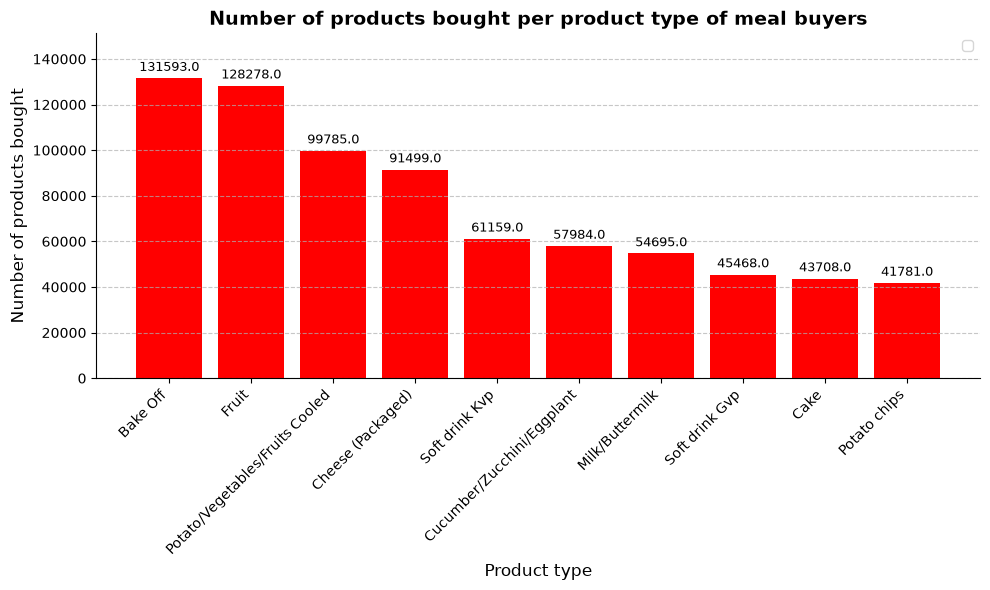

In [ ]:
# Example chart
meal_buyer_df = df[df["CONSUMER_TYPE"] == "Meal buyer"].copy()
meal_buyer_product_type_total_product_count = meal_buyer_df.groupby("PRODUCT_TYPE")["AMOUNT_OF_PRODUCT_UNITS"].sum().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 6), dpi=100)
bars = plt.bar(meal_buyer_product_type_total_product_count.index, meal_buyer_product_type_total_product_count.values, color = "red")

plt.bar_label(bars, fmt='%.1f', padding=3, fontsize=9)

plt.title('Number of products bought per product type of meal buyers', fontsize=14, fontweight='bold')
plt.xlabel('Product type', fontsize=12)
plt.ylabel('Number of products bought', fontsize=12)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

plt.ylim(0, meal_buyer_product_type_total_product_count.values.max() * 1.15)

plt.grid(axis='y', linestyle='--', alpha=0.7, zorder=0)
plt.legend(loc='upper right')
plt.tight_layout()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()